# Statistics of a map, with masks, cross statistics and gradients

This tutorial computes the scattering-covariance statistics of the Takahashi κ map with the Python
engine `NativeEngine`: the plan, the statistics per family, their spatial variances (ergodic error
bars), averages over masks, cross statistics of two maps, and the exact gradient.

`NativeEngine` loads `libstl_bridge.so` (`cargo build --release -p stl-bridge --features gpu`,
`STL_NATIVE_LIBRARY`). The map is the Takahashi κ map at nside 64 of `fixtures/takahashi/`.
Everything here runs in about a minute on a CPU.

In [1]:
import json, os, subprocess, sys, time
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

ROOT = Path.cwd()
while not (ROOT / "Cargo.toml").exists():          # the repository root, from docs/tutorials
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "examples"))
sys.path.insert(0, str(ROOT / "python" / "stl_ensemble"))
BIN = Path(os.environ.get("STL_BIN", ROOT / "target" / "release"))
WORK = Path(os.environ.get("STL_WORK", ROOT / "docs" / "tutorials" / "out")); WORK.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"figure.dpi": 80, "image.cmap": "plasma"})

def run(*args):
    """Runs a command-line tool, prints its last lines and its wall-clock time."""
    t0 = time.time()
    p = subprocess.run([str(a) for a in args], capture_output=True, text=True)
    if p.returncode:
        raise RuntimeError(p.stderr[-2000:])
    print(p.stdout.strip()[-600:], f"\n[{time.time() - t0:.1f} s]")

In [2]:
from stl_port.native import NativeEngine
kappa = np.load(ROOT / "fixtures/takahashi/takahashi_r000_zs1_nside64_nested.npy").astype(np.float64)
x = (kappa - kappa.mean()) / kappa.std()
nside, j = 64, 5
eng = NativeEngine(nside, j, batch=1, backend="cpu", threads=8)
plan = eng.plan
fam = np.array([c["family"] for c in plan])
print(len(plan), "coefficients:", {str(f): int((fam == f).sum()) for f in dict.fromkeys(fam)})
print("one coefficient of each family:", [plan[int(np.flatnonzero(fam == f)[0])] for f in ("S1", "S3", "S4")])

SCRIPT VERSION: stl_port 2026-10-29-v2-variance-ratio


SCRIPT VERSION: stl_port.native 2026-11-06-v6


2522 coefficients: {'mean': 1, 'var': 1, 'S1': 20, 'S2': 20, 'S3': 240, 'S4': 2240}
one coefficient of each family: [{'c1': 0, 'c2': 0, 'family': 'S1', 'index': 2, 'j1': 0, 'j2': None, 'j3': None, 'l1': 0, 'l2': None, 'l3': None, 'native_dg': 0}, {'c1': 0, 'c2': 0, 'family': 'S3', 'index': 10, 'j1': 0, 'j2': None, 'j3': 0, 'l1': 0, 'l2': None, 'l3': 0, 'native_dg': 0}, {'c1': 0, 'c2': 0, 'family': 'S4', 'index': 26, 'j1': 0, 'j2': 0, 'j3': 0, 'l1': 0, 'l2': 0, 'l3': 0, 'native_dg': 0}]


## 1. Statistics and ergodic error bars

`forward(x, moments=True)` returns the values and the spatial variance of each coefficient's
terms; divided by the number of pixels each coefficient averages (`native_pixels()`), it estimates
the variance of the coefficient between realisations (under ergodicity).

forward: 7.99 s


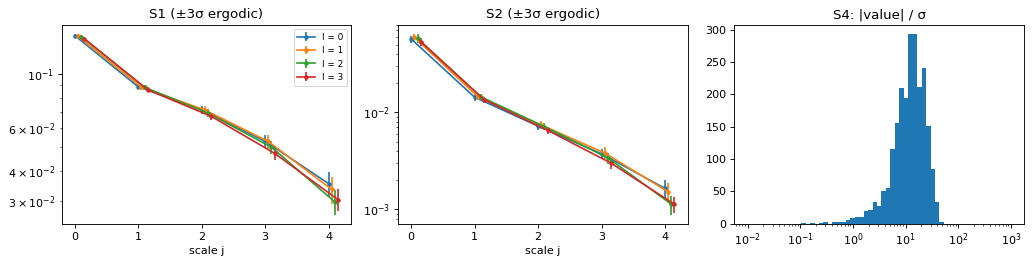

In [3]:
t0 = time.time(); s, var = eng.forward(x, moments=True); print(f"forward: {time.time() - t0:.2f} s")
s, var = s[0], var[0]
sigma = np.sqrt(var / eng.native_pixels())
j1 = np.array([c["j1"] for c in plan]); l1 = np.array([c["l1"] for c in plan])
fig, ax = plt.subplots(1, 3, figsize=(13, 3.4))
for k, f in enumerate(["S1", "S2"]):
    for l in range(4):
        sel = (fam == f) & (l1 == l)
        ax[k].errorbar(j1[sel] + 0.05 * l, s[sel].real, 3 * sigma[sel], fmt="o-", ms=3, label=f"l = {l}")
    ax[k].set_yscale("log"); ax[k].set_xlabel("scale j"); ax[k].set_title(f"{f} (±3σ ergodic)")
ax[0].legend(fontsize=8)
sel = fam == "S4"
ax[2].hist(np.abs(s[sel]) / sigma[sel], bins=np.logspace(-2, 3, 60)); ax[2].set_xscale("log")
ax[2].set_title("S4: |value| / σ"); plt.tight_layout(); plt.show()

## 2. Masks

With `K` masks, every coefficient is averaged over each mask at its native level (the wavelets and
moduli stay those of the full sky). Here: the whole sky, and the pixels of latitude
`|lat| > 20°` and `|lat| > 45°` of the HEALPix grid (galactic cuts of a real sky would be the same). The values become `[batch, K, ncoeff]`.

forward with 3 masks: 8.19 s
full sky equals mask 0: True


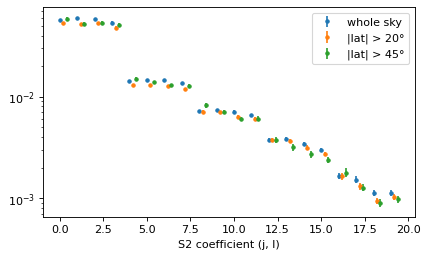

In [4]:
from healpix_geo.nested import healpix_to_lonlat
lon, lat = healpix_to_lonlat(np.arange(12 * nside**2), int(np.log2(nside)), ellipsoid="sphere")
masks = [np.arange(lat.size), np.flatnonzero(np.abs(lat) > 20), np.flatnonzero(np.abs(lat) > 45)]
eng.set_masks(masks)
t0 = time.time(); sm, varm = eng.forward(x, moments=True); print(f"forward with 3 masks: {time.time() - t0:.2f} s")
sm, sigm = sm[0], np.sqrt(varm[0] / eng.native_pixels())
print("full sky equals mask 0:", np.allclose(sm[0], s, rtol=1e-12, atol=1e-14))
sel = fam == "S2"
plt.figure(figsize=(6, 3.4))
for k, name in enumerate(["whole sky", "|lat| > 20°", "|lat| > 45°"]):
    plt.errorbar(np.arange(sel.sum()) + 0.2 * k, sm[k, sel].real, sigm[k, sel], fmt=".", label=name)
plt.yscale("log"); plt.xlabel("S2 coefficient (j, l)"); plt.legend(); plt.show()
eng.set_masks(None)

## 3. Cross statistics

`cross=True` gives the statistics `S(a, b)` of two maps (the terms with `c1 ≠ c2`; S3 and S4 in
both orders). Here κ against its Gaussianised version `g`, which has the same phases.

In [5]:
from scipy.stats import norm
g = np.empty_like(x); g[np.argsort(x)] = norm.ppf((np.arange(x.size) + 0.5) / x.size)
ce = NativeEngine(nside, j, batch=1, cross=True, threads=8)
cfam = np.array([c["family"] for c in ce.plan])
sc, _ = ce.forward_cross(x[None], g[None])
print(len(ce.plan), "cross coefficients:", {str(f): int((cfam == f).sum()) for f in dict.fromkeys(cfam)})
sel = cfam == "S2"
print("cross S2 <z_kappa conj z_g> per scale (orientation 0):", np.round(sc[0, sel].real[::4], 4))

5000 cross coefficients: {'S1': 20, 'S2': 20, 'S3': 480, 'S4': 4480}
cross S2 <z_kappa conj z_g> per scale (orientation 0): [0.0362 0.0137 0.0089 0.0052 0.0025]


## 4. Exact gradient

`vjp` returns the gradient of `Re Σ conj(c_i) S_i` with respect to the map. For the loss
`Σ_i w_i |S_i(y) − S_i(x)|²` the cotangent is `2 w (S(y) − S(x))`. A directional finite difference
confirms it.

In [6]:
w = 1 / sigma**2
y = np.random.default_rng(1).standard_normal(x.size)
def loss(m):
    v, _ = eng.forward(m)
    return float(np.sum(w * np.abs(v[0] - s) ** 2)), v[0]
L0, v0 = loss(y)
t0 = time.time(); grad = eng.vjp(2 * w * (v0 - s))[0]; print(f"vjp: {time.time() - t0:.2f} s")
d = np.random.default_rng(2).standard_normal(x.size); eps = 1e-4
fd = (loss(y + eps * d)[0] - loss(y - eps * d)[0]) / (2 * eps)
print(f"loss {L0:.6e}; <grad, d> = {grad @ d:.8e}, finite difference {fd:.8e}, relative difference {abs(grad @ d / fd - 1):.1e}")

vjp: 11.65 s


loss 6.581715e+05; <grad, d> = -5.50105328e+03, finite difference -5.50105186e+03, relative difference 2.6e-07
